# 2.5 - Clasificación multiclase: precio de smartphones

Predeciremos la **categoría de precio de un smartphone** a partir de sus 20 características técnicas. El objetivo `price_range` tiene cuatro clases: **0 = económico, 1 = medio, 2 = alto y 3 = muy alto**. Son categorías de precio, no importes monetarios.

Seguiremos un método sencillo:

1. Cargar los datos y revisar la distribución del target.
2. Separar entrenamiento y test con una partición estratificada.
3. Transformar las variables y normalizarlas usando solo entrenamiento.
4. Definir una red neuronal densa.
5. Elegir la función de pérdida y el optimizador.
6. Entrenar mostrando únicamente **accuracy** como métrica.
7. Representar la pérdida y accuracy y, después, precision, recall y F1.
8. Evaluar el modelo y mostrar las matrices de confusión.

Separamos antes de ajustar el preprocesado para que test no participe en el aprendizaje de escalas o categorías. Usamos **solo entrenamiento y test**, sin tercer conjunto.

**Notebook preparado sin ejecutar.** Los resultados y las gráficas se generarán al ejecutar las celdas. Referencia de las métricas: `BonusTrack_03_Evaluacion_Modelos_Clasificacion.ipynb`.

**Material de origen:** `6_01_05_Ejercicio_Redes_Neuronales_Clasificacion.ipynb`.

---
## 1. Carga de datos

Utilizamos el CSV de la asignatura. Las etiquetas se conservan como enteros; el target no se normaliza.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    log_loss, classification_report, ConfusionMatrixDisplay,
)
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import Callback

SEMILLA = 42
tf.keras.utils.set_random_seed(SEMILLA)
plt.rcParams.update({"figure.dpi": 120, "font.size": 11})

rutas = [Path("datasets/Mobile_Price_Classification.csv"), Path("MUIA_RNMU/datasets/Mobile_Price_Classification.csv")]
ruta = next((p for p in rutas if p.is_file()), None)
if ruta is None:
    raise FileNotFoundError("Abre el notebook desde MUIA_RNMU o su carpeta superior.")
df = pd.read_csv(ruta)
target_col = "price_range"
CLASES = np.array([0, 1, 2, 3])
NOMBRES = ['Económico', 'Medio', 'Alto', 'Muy alto']
display(df.head(5))
print(f"{len(df):,} observaciones y {df.shape[1] - 1} variables de entrada.")
if df.isna().any().any():
    raise ValueError("Hay valores ausentes: revisa su tratamiento antes de continuar.")

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


2,000 observaciones y 20 variables de entrada.


### 1.1. Distribución del target

Contamos las observaciones y el porcentaje de cada clase y mostramos un gráfico de barras. Una accuracy elevada puede ocultar un mal resultado en una clase minoritaria: también examinaremos precision, recall y F1.

,Clase,Significado,Observaciones,Porcentaje
0,0,Económico,500,25.0
1,1,Medio,500,25.0
2,2,Alto,500,25.0
3,3,Muy alto,500,25.0


Clases perfectamente balanceadas: todas tienen el mismo número de ejemplos.


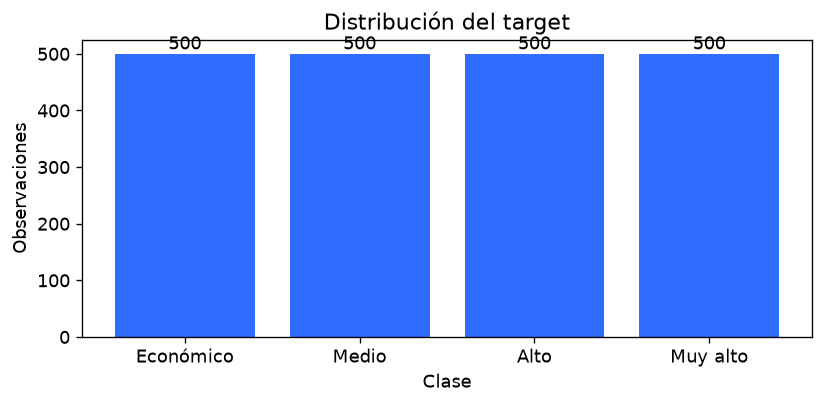

In [2]:
conteos = df[target_col].value_counts().reindex(CLASES, fill_value=0)
distribucion = pd.DataFrame({
    "Clase": CLASES,
    "Significado": NOMBRES,
    "Observaciones": conteos.to_numpy(),
    "Porcentaje": 100 * conteos.to_numpy() / len(df),
})
display(distribucion)
if (conteos == 0).any():
    raise ValueError("Faltan clases esperadas en el CSV.")
if conteos.nunique() == 1:
    print("Clases perfectamente balanceadas: todas tienen el mismo número de ejemplos.")
else:
    print(f"Frecuencias distintas. Razón mayoritaria/minoritaria: {conteos.max()/conteos.min():.2f}.")
    print("Valora el desbalance junto con los errores de cada clase.")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(NOMBRES, conteos.to_numpy(), color="#2F6BFF")
ax.set(title="Distribución del target", xlabel="Clase", ylabel="Observaciones")
ax.bar_label(ax.containers[0])
fig.tight_layout()
plt.show()

En el CSV proporcionado hay **500 smartphones por clase (25 % cada una)**: las cuatro clases están balanceadas. Comprobamos esta distribución al cargarlo en lugar de suponerla.

---
## 2. Partición en entrenamiento y test

Reservamos el 20 % para test. `stratify=y` conserva aproximadamente la proporción de clases de la muestra. Test no actualiza los pesos y no se utiliza para elegir épocas, arquitectura, umbral ni hiperparámetros.

In [3]:
X = df.drop(columns=target_col).copy()
y = df[target_col].astype("int32")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y
)
y_train_array = y_train.to_numpy()
y_test_array = y_test.to_numpy()
print(f"Entrenamiento: {len(X_train)} | Test: {len(X_test)}")
display(pd.DataFrame({
    "Train (%)": y_train.value_counts(normalize=True).reindex(CLASES) * 100,
    "Test (%)": y_test.value_counts(normalize=True).reindex(CLASES) * 100,
}))

Entrenamiento: 1600 | Test: 400


,Train (%),Test (%)
price_range,,
0,25.0,25.0
1,25.0,25.0
2,25.0,25.0
3,25.0,25.0


---
## 3. Transformación y normalización

Las variables numéricas se escalan con **MinMaxScaler**. Las categóricas se representan mediante **one-hot**, sin inventar un orden. Los codificadores y el escalador se ajustan solo con entrenamiento y se reutilizan en test.

Las características del CSV de smartphones ya son numéricas, incluidas las variables binarias 0/1. No hacemos one-hot del target: las clases 0–3 se usarán directamente con la pérdida sparse.

In [4]:
numericas = X_train.select_dtypes(include="number").columns.tolist()
categoricas = X_train.select_dtypes(exclude="number").columns.tolist()
preprocesador = ColumnTransformer([
    ("numericas", MinMaxScaler(), numericas),
    ("categoricas", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoricas),
], sparse_threshold=0)

X_train_n = preprocesador.fit_transform(X_train).astype("float32")
X_test_n = preprocesador.transform(X_test).astype("float32")
print("Dimensión de entrada tras transformar:", X_train_n.shape[1])
display(pd.DataFrame(X_train_n[:5], columns=preprocesador.get_feature_names_out()))

Dimensión de entrada tras transformar: 20


,numericas__battery_power,numericas__blue,numericas__clock_speed,numericas__dual_sim,numericas__fc,numericas__four_g,numericas__int_memory,numericas__m_dep,numericas__mobile_wt,numericas__n_cores,numericas__pc,numericas__px_height,numericas__px_width,numericas__ram,numericas__sc_h,numericas__sc_w,numericas__talk_time,numericas__three_g,numericas__touch_screen,numericas__wifi
0,0.135605,0.0,0.68,1.0,0.210526,0.0,0.822581,0.111111,0.883333,0.714286,0.3,0.130729,0.342685,0.907754,0.142857,0.055556,0.722222,1.0,1.0,1.0
1,0.124917,1.0,0.40,0.0,0.000000,0.0,0.000000,1.000000,0.075000,0.285714,0.1,0.141146,0.246493,0.035561,0.000000,0.111111,0.333333,1.0,1.0,1.0
2,0.818971,1.0,0.64,1.0,0.526316,0.0,0.887097,0.222222,0.650000,0.714286,0.9,0.195833,0.526386,0.067914,0.000000,0.111111,0.222222,0.0,0.0,0.0
3,0.630595,1.0,0.00,0.0,0.000000,0.0,0.822581,0.666667,0.783333,0.857143,0.7,0.201042,0.224449,0.224866,0.857143,0.055556,1.000000,1.0,0.0,0.0
4,0.832331,0.0,0.00,0.0,0.210526,0.0,0.177419,0.666667,0.875000,0.714286,0.6,0.416667,0.249165,0.761230,0.142857,0.055556,0.444444,1.0,0.0,0.0


---
## 4. Arquitectura de la red neuronal

Usamos dos capas ocultas sencillas: **32 y 16 neuronas con ReLU**.

La salida tiene **cuatro neuronas softmax**, una por clase. Devuelve un vector de probabilidades que suma 1. La clase predicha es la de mayor probabilidad (`argmax`).

In [5]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEMILLA)
model = Sequential([
    Input(shape=(X_train_n.shape[1],)),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(4, activation="softmax"),
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 32)                  │             672 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 4)                   │              68 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,268 (4.95 KB)

 Trainable params: 1,268 (4.95 KB)

 Non-trainable params: 0 (0.00 B)

---
## 5. Pérdida, optimizador y métrica de entrenamiento

Elegimos **sparse categorical crossentropy** porque el target contiene índices enteros de clase, no vectores one-hot. Si el target fuera one-hot, correspondería `categorical_crossentropy`.

Usamos **Adam**, con tasa de aprendizaje 0,001. La única métrica de `compile` es **accuracy**. Precision, recall y F1 se calcularán después del entrenamiento.

In [6]:
EPOCHS = 50
BATCH_SIZE = 32
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

---
## 6. Entrenamiento: mostramos solo accuracy

Al acabar cada época, guardamos las probabilidades de entrenamiento y test con los mismos pesos. El callback **solo muestra accuracy**. Una vez finalizado `fit`, utilizaremos las probabilidades guardadas para calcular todas las curvas, sin reentrenar ni modificar los pesos.

Las predicciones se guardan en memoria para este ejemplo pequeño. Las consultas a test son solo didácticas: si decidimos cambios mirando esas curvas, test deja de ser una evaluación final independiente. No usamos `validation_data` ni un tercer conjunto.

In [7]:
def obtener_clases(probabilidades):
    return np.argmax(probabilidades, axis=1)


class GuardarEvolucion(Callback):
    def on_train_begin(self, logs=None):
        self.probabilidades_por_epoch = []

    def on_epoch_end(self, epoch, logs=None):
        p_train = self.model(X_train_n, training=False).numpy()
        p_test = self.model(X_test_n, training=False).numpy()
        self.probabilidades_por_epoch.append((p_train, p_test))
        acc_train = accuracy_score(y_train_array, obtener_clases(p_train))
        acc_test = accuracy_score(y_test_array, obtener_clases(p_test))
        print(f"Epoch {epoch + 1:02d}/{self.params['epochs']} | "
              f"accuracy train: {acc_train:.4f} | accuracy test: {acc_test:.4f}")


seguimiento = GuardarEvolucion()
history = model.fit(
    X_train_n, y_train_array,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    callbacks=[seguimiento], shuffle=True, verbose=0,
)

Epoch 01/50 | accuracy train: 0.2900 | accuracy test: 0.3025
Epoch 02/50 | accuracy train: 0.3281 | accuracy test: 0.3325
Epoch 03/50 | accuracy train: 0.3931 | accuracy test: 0.3600
Epoch 04/50 | accuracy train: 0.4662 | accuracy test: 0.4400
Epoch 05/50 | accuracy train: 0.5975 | accuracy test: 0.5475
Epoch 06/50 | accuracy train: 0.6913 | accuracy test: 0.6700
Epoch 07/50 | accuracy train: 0.7394 | accuracy test: 0.7450
Epoch 08/50 | accuracy train: 0.7675 | accuracy test: 0.7875
Epoch 09/50 | accuracy train: 0.7844 | accuracy test: 0.8050
Epoch 10/50 | accuracy train: 0.8019 | accuracy test: 0.8225
Epoch 11/50 | accuracy train: 0.8200 | accuracy test: 0.8325
Epoch 12/50 | accuracy train: 0.8313 | accuracy test: 0.8600
Epoch 13/50 | accuracy train: 0.8469 | accuracy test: 0.8725
Epoch 14/50 | accuracy train: 0.8575 | accuracy test: 0.8825
Epoch 15/50 | accuracy train: 0.8694 | accuracy test: 0.8925
Epoch 16/50 | accuracy train: 0.8781 | accuracy test: 0.8950
Epoch 17/50 | accuracy t

---
## 7. Cálculo de las métricas después de entrenar

* **Accuracy:** proporción global de etiquetas correctas.
* **Precision:** de los positivos predichos, proporción que realmente es positiva.
* **Recall:** de los positivos reales, proporción detectada.
* **F1:** media armónica de precision y recall.

En multiclase calculamos precision, recall y F1 **macro**: cada clase se considera positiva frente al resto y se promedian los resultados dando el mismo peso a cada clase. F1 macro es el promedio de los F1 individuales, no la media armónica de precision macro y recall macro.

Usamos `zero_division=0`: si no hay predicciones positivas para una clase, una división no definida se representa como 0. La pérdida se calcula con las probabilidades; las otras métricas, con las clases predichas.

In [8]:
def calcular_metricas(reales, probabilidades):
    predichas = obtener_clases(probabilidades)
    return {
        "loss": log_loss(reales, probabilidades, labels=CLASES),
        "accuracy": accuracy_score(reales, predichas),
        "precision": precision_score(reales, predichas, average="macro", labels=CLASES, zero_division=0),
        "recall": recall_score(reales, predichas, average="macro", labels=CLASES, zero_division=0),
        "f1": f1_score(reales, predichas, average="macro", labels=CLASES, zero_division=0),
    }


registros = []
for epoch, (p_train, p_test) in enumerate(seguimiento.probabilidades_por_epoch, start=1):
    fila = {"epoch": epoch}
    for nombre, reales, probabilidades in [
        ("train", y_train_array, p_train), ("test", y_test_array, p_test)
    ]:
        for metrica, valor in calcular_metricas(reales, probabilidades).items():
            fila[f"{metrica}_{nombre}"] = valor
    registros.append(fila)
evolucion = pd.DataFrame(registros).set_index("epoch")
display(evolucion.tail(5))

,loss_train,accuracy_train,precision_train,recall_train,f1_train,loss_test,accuracy_test,precision_test,recall_test,f1_test
epoch,,,,,,,,,,
46,0.118609,0.965000,0.965857,0.965000,0.965018,0.152622,0.9375,0.940078,0.9375,0.937365
47,0.115622,0.965625,0.966522,0.965625,0.965640,0.150845,0.9375,0.940078,0.9375,0.937365
48,0.112873,0.966875,0.967718,0.966875,0.966899,0.149388,0.9400,0.942171,0.9400,0.939804
49,0.110072,0.968125,0.968984,0.968125,0.968152,0.147274,0.9400,0.942171,0.9400,0.939804
50,0.107454,0.970625,0.971276,0.970625,0.970648,0.145859,0.9400,0.942171,0.9400,0.939804


---
## 8. Curvas de entrenamiento y test

Primero representamos **pérdida y accuracy** en una fila de dos columnas. Después, **precision, recall y F1** en otra fila de tres columnas. Se muestran todas las épocas. Azul indica entrenamiento y rojo test.

Estos valores se calculan al terminar cada época, con los mismos pesos para los dos conjuntos. Pueden diferir de los promedios internos por lote que registra `history`, porque durante una época los pesos van cambiando.

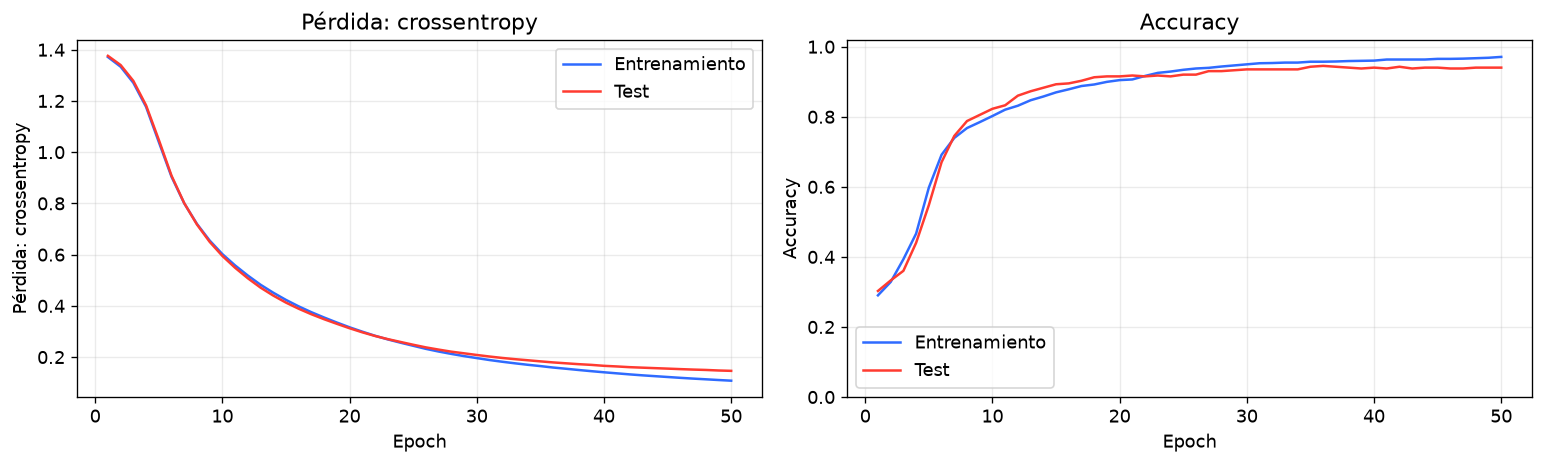

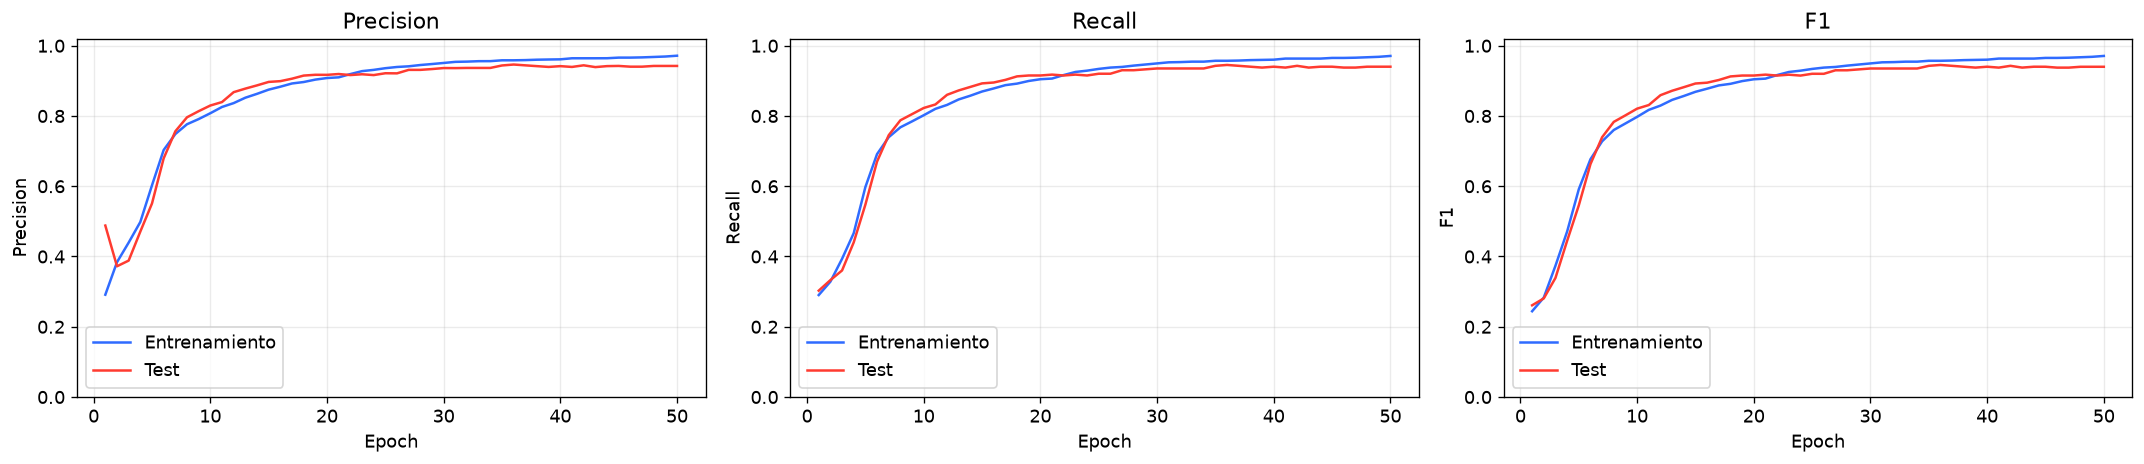

In [9]:
def dibujar_metrica(ax, metrica, titulo, es_proporcion=True):
    ax.plot(evolucion.index, evolucion[f"{metrica}_train"],
            color="#2F6BFF", label="Entrenamiento")
    ax.plot(evolucion.index, evolucion[f"{metrica}_test"],
            color="#FF3B30", label="Test")
    ax.set(title=titulo, xlabel="Epoch", ylabel=titulo)
    if es_proporcion:
        ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.25)
    ax.legend()


fig, axes = plt.subplots(1, 2, figsize=(13, 4))
dibujar_metrica(axes[0], "loss", "Pérdida: crossentropy", es_proporcion=False)
dibujar_metrica(axes[1], "accuracy", "Accuracy")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, metrica, titulo in zip(axes, ["precision", "recall", "f1"], ["Precision", "Recall", "F1"]):
    dibujar_metrica(ax, metrica, titulo)
fig.tight_layout()
plt.show()

---
## 9. Evaluación final y resultados por clase

Calculamos las métricas finales sobre entrenamiento y test y mostramos un informe por clase. Como referencia sencilla, calculamos la accuracy de predecir siempre la clase mayoritaria **del entrenamiento**.

Consulta `BonusTrack_03_Evaluacion_Modelos_Clasificacion.ipynb` para ver los cálculos de las métricas con ejemplos pequeños y la interpretación de los promedios.

In [10]:
p_train_final = model.predict(X_train_n, verbose=0)
p_test_final = model.predict(X_test_n, verbose=0)
pred_train = obtener_clases(p_train_final)
pred_test = obtener_clases(p_test_final)

resultados = pd.DataFrame({
    "Entrenamiento": calcular_metricas(y_train_array, p_train_final),
    "Test": calcular_metricas(y_test_array, p_test_final),
}).T
display(resultados)
clase_mayoritaria = y_train.value_counts().idxmax()
pred_base = np.full(len(y_test_array), clase_mayoritaria)
print(f"Accuracy base en test (siempre clase {clase_mayoritaria}): "
      f"{accuracy_score(y_test_array, pred_base):.4f}")

for nombre, reales, predichas in [
    ("Entrenamiento", y_train_array, pred_train),
    ("Test", y_test_array, pred_test),
]:
    print(f"\n{nombre}")
    print(classification_report(reales, predichas, labels=CLASES,
                                target_names=NOMBRES, zero_division=0, digits=4))

,loss,accuracy,precision,recall,f1
Entrenamiento,0.107454,0.970625,0.971276,0.970625,0.970648
Test,0.145859,0.940000,0.942171,0.940000,0.939804


Accuracy base en test (siempre clase 2): 0.2500

Entrenamiento
              precision    recall  f1-score   support

   Económico     0.9974    0.9525    0.9744       400
       Medio     0.9424    0.9825    0.9621       400
        Alto     0.9770    0.9550    0.9659       400
    Muy alto     0.9683    0.9925    0.9802       400

    accuracy                         0.9706      1600
   macro avg     0.9713    0.9706    0.9706      1600
weighted avg     0.9713    0.9706    0.9706      1600


Test
              precision    recall  f1-score   support

   Económico     0.9792    0.9400    0.9592       100
       Medio     0.8889    0.9600    0.9231       100
        Alto     0.9667    0.8700    0.9158       100
    Muy alto     0.9340    0.9900    0.9612       100

    accuracy                         0.9400       400
   macro avg     0.9422    0.9400    0.9398       400
weighted avg     0.9422    0.9400    0.9398       400



### 9.1. Comparación visual de las métricas finales

El panel de **dos filas y dos columnas** compara entrenamiento (azul) y test (naranja) para el único modelo de red neuronal. Cada pareja de barras representa accuracy, precision, recall o F1 al finalizar el entrenamiento. Todos los ejes tienen la misma escala y las barras muestran el valor numérico.

Precision, recall y F1 son promedios macro, con el mismo peso para cada clase.

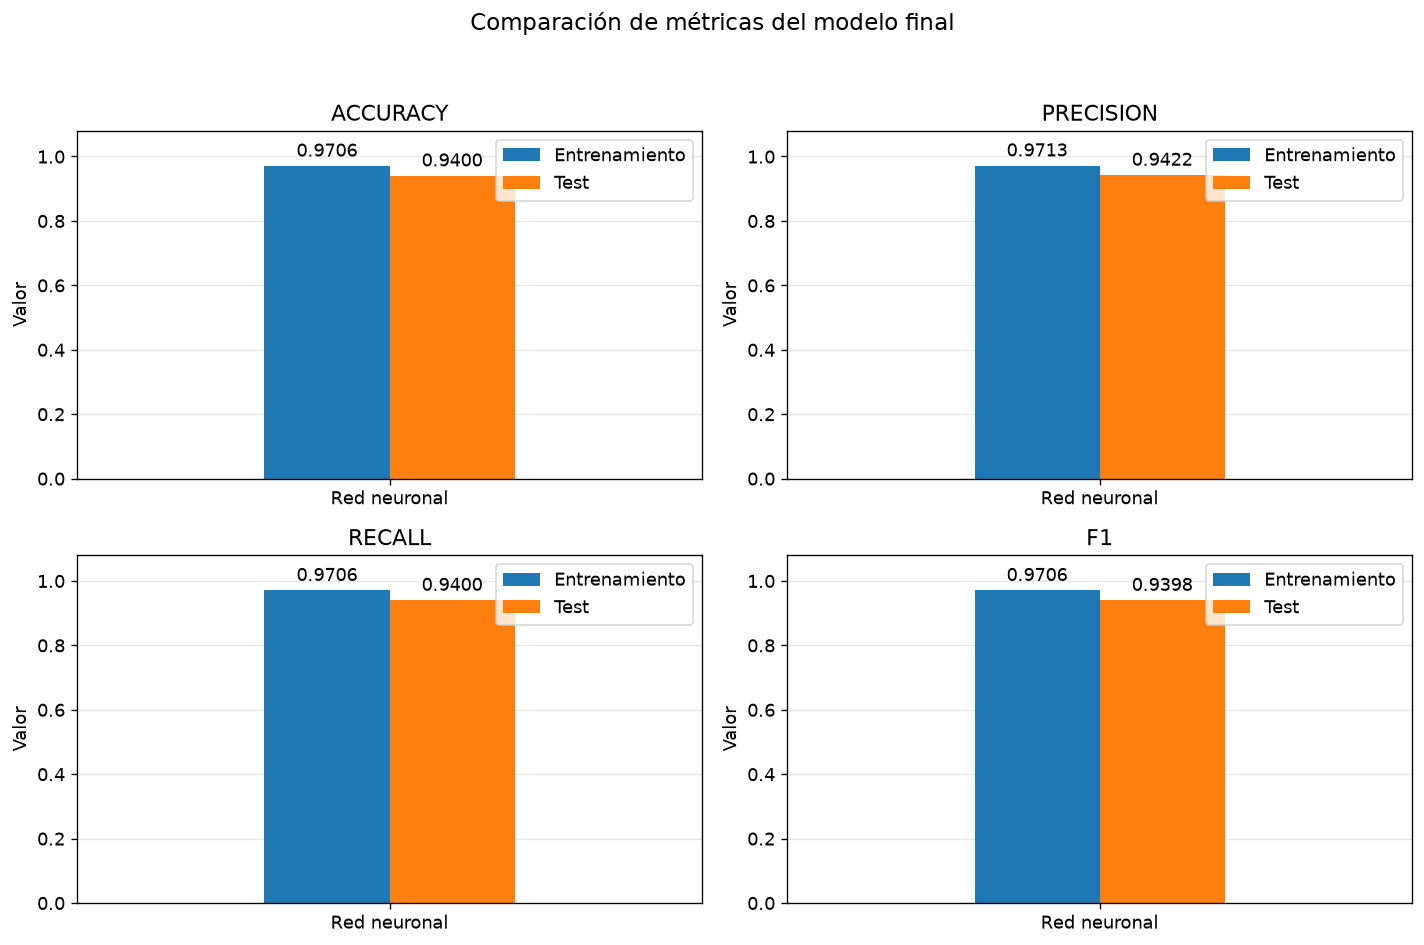

In [11]:
metricas_panel = ["accuracy", "precision", "recall", "f1"]
titulos_panel = ["ACCURACY", "PRECISION", "RECALL", "F1"]
comparacion_metricas = resultados.loc[["Entrenamiento", "Test"], metricas_panel]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
ancho = 0.32
for ax, metrica, titulo in zip(axes.flat, metricas_panel, titulos_panel):
    valor_train = float(comparacion_metricas.loc["Entrenamiento", metrica])
    valor_test = float(comparacion_metricas.loc["Test", metrica])
    barras_train = ax.bar(-ancho / 2, valor_train, width=ancho, label="Entrenamiento")
    barras_test = ax.bar(ancho / 2, valor_test, width=ancho, label="Test")
    ax.bar_label(barras_train, fmt="%.4f", padding=3)
    ax.bar_label(barras_test, fmt="%.4f", padding=3)
    ax.set(title=titulo, ylabel="Valor", ylim=(0, 1.08), xlim=(-0.8, 0.8))
    ax.set_xticks([0], ["Red neuronal"])
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(loc="upper right")

fig.suptitle("Comparación de métricas del modelo final", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

---
## 10. Matrices de confusión

Las **filas representan clases reales** y las **columnas clases predichas**. La diagonal contiene los aciertos. Usamos el mismo orden de clases en los dos conjuntos y mostramos **recuentos**, no porcentajes.

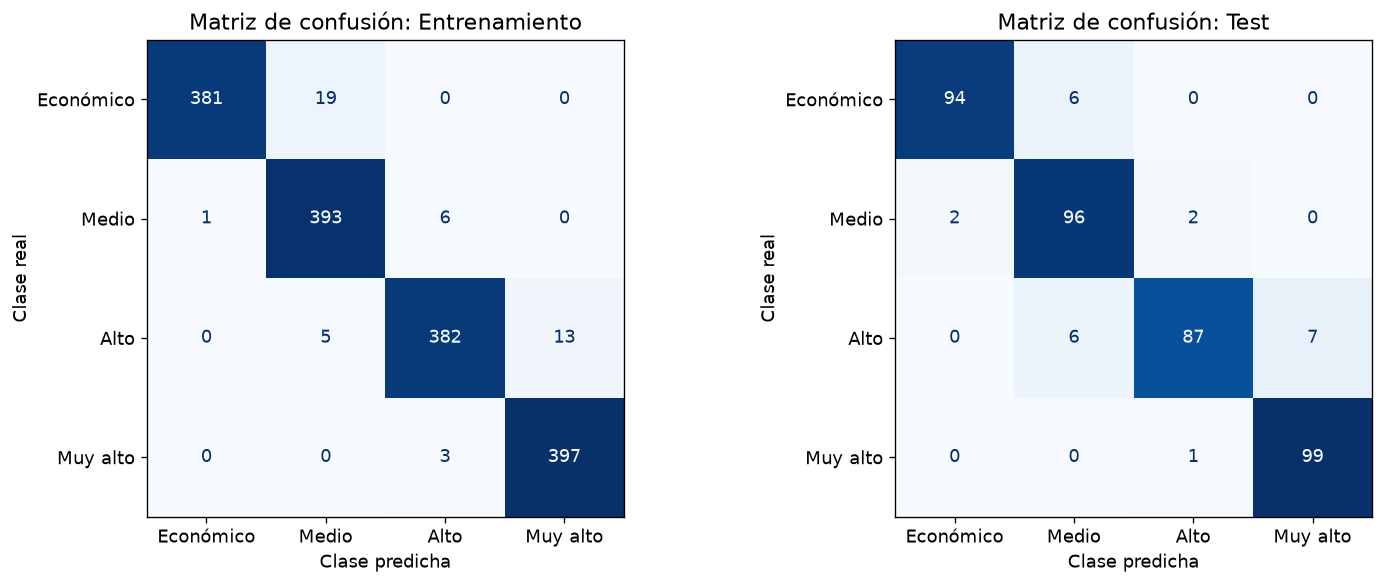

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, reales, predichas, titulo in [
    (axes[0], y_train_array, pred_train, "Entrenamiento"),
    (axes[1], y_test_array, pred_test, "Test"),
]:
    ConfusionMatrixDisplay.from_predictions(
        reales, predichas, labels=CLASES, display_labels=NOMBRES,
        values_format="d", cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set(title=f"Matriz de confusión: {titulo}",
           xlabel="Clase predicha", ylabel="Clase real")
fig.tight_layout()
plt.show()

### Preguntas para interpretar los resultados

* ¿Supera el modelo al clasificador de la clase mayoritaria?
* ¿Qué clases detecta mejor y cuáles confunde?
* ¿Son parecidos los errores en entrenamiento y test?
* ¿Qué información añade F1 a accuracy?
